# Where will the rain fall? The next 10 days at 9 km 🌧️
### ECMWF free & open data · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/unicef/rain_forecast.ipynb)

ECMWF's forecasts are **open data**: anyone can download them, with no login and no fee, under a CC-BY-4.0 licence.
This notebook pulls the latest **9 km** forecast of total rainfall for the next ten days and maps it for a country
where UNICEF works. It starts with the **Philippines**, where UNICEF responded to Super Typhoon Fung-wong (Uwan) in
November 2025. Switch to **Somalia** and the map takes in the Ethiopian highlands, where the Juba and Shabelle rivers
that flood Beledweyne begin.

*In Google Colab? Press **Runtime → Run all**. Nothing to install on your own computer.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the place and the period

Pick any country from the list (or add your own with a `[west, east, south, north]` box), and how many days
of rain to add up (1 to 15).

In [3]:
# Countries where UNICEF responded to, or prepared for, weather and climate hazards in 2025-26
PLACES = {
    "Somalia":     dict(domain=[36.5, 51.6, -2.5, 12.5],      # with the Ethiopian highlands that feed the rivers
                        cities=[("Mogadishu", 2.046, 45.318), ("Beledweyne", 4.736, 45.204), ("Baidoa", 3.114, 43.650),
                                ("Kismayo", -0.358, 42.545), ("Garowe", 8.406, 48.483), ("Hargeisa", 9.560, 44.065)]),
    "Mozambique":  dict(domain=[30.0, 41.0, -27.0, -10.3],
                        cities=[("Maputo", -25.966, 32.583), ("Xai-Xai", -25.052, 33.644), ("Beira", -19.844, 34.839),
                                ("Nampula", -15.116, 39.266)]),
    "Malawi":      dict(domain=[32.0, 36.5, -17.4, -9.2],
                        cities=[("Lilongwe", -13.963, 33.775), ("Blantyre", -15.786, 35.006), ("Nsanje", -16.920, 35.262)]),
    "Madagascar":  dict(domain=[42.8, 51.0, -26.0, -11.7],
                        cities=[("Antananarivo", -18.879, 47.508), ("Toamasina", -18.149, 49.402), ("Toliara", -23.354, 43.669)]),
    "Philippines": dict(domain=[116.5, 127.0, 4.5, 21.0],
                        cities=[("Manila", 14.600, 120.984), ("Virac", 13.580, 124.230), ("Tacloban", 11.244, 125.004),
                                ("Cebu", 10.316, 123.891), ("Davao", 7.190, 125.455)]),
    "Honduras":    dict(domain=[-89.5, -83.0, 12.8, 16.6],
                        cities=[("Tegucigalpa", 14.072, -87.192), ("San Pedro Sula", 15.506, -88.025), ("Choluteca", 13.300, -87.193)]),
    "Chad":        dict(domain=[13.4, 24.1, 7.4, 23.5],
                        cities=[("N'Djamena", 12.134, 15.055), ("Moussoro", 13.641, 16.490), ("Mao", 14.119, 15.313)]),
    "Pakistan":    dict(domain=[60.8, 77.9, 23.6, 37.1],
                        cities=[("Islamabad", 33.684, 73.048), ("Peshawar", 34.015, 71.524), ("Lahore", 31.520, 74.359),
                                ("Karachi", 24.861, 67.010)]),
}

PLACE = "Philippines"
DAYS  = 10

## 2 · Get the forecast (ECMWF open data, 9 km)

One request. `resol="0p1"` asks for the 0.1° grid (~9 km); `step` is hours from the start of the forecast.
Rainfall (`tp`) is accumulated from the start, so the field at `24 × DAYS` hours *is* the total.

In [4]:
rain = ekd.from_source("ecmwf-open-data", time=0, step=24 * DAYS, stream="oper", type="fc",
                      param="tp", resol="0p1").to_fieldlist()
f = rain[0]
start, end = f.time.base_datetime(), f.time.valid_datetime()
print(f"Forecast from {start:%A %d %B %Y %H} UTC, total rain to {end:%A %d %B %H} UTC")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Forecast from Tuesday 17 November 2026 00 UTC, total rain to Friday 27 November 00 UTC


## 3 · Map it

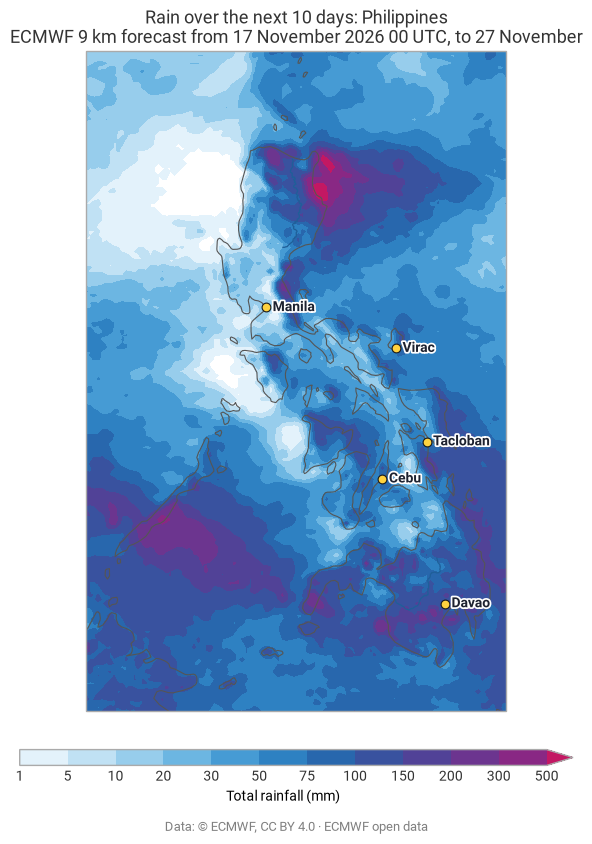

In [5]:
def label_cities(chart, cities, ink="#1d2230", halo="white"):
    for name, lat, lon in cities:
        chart.scatter(x=[lon], y=[lat], s=40, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lon, lat, f"  {name}", ha="left", va="center", fontsize=10, fontweight="bold", color=ink, zorder=11,
                      transform=ccrs.PlateCarree(), path_effects=[pe.withStroke(linewidth=2.5, foreground=halo)])

P = PLACES[PLACE]
chart = ekp.Map(domain=P["domain"])
rain_style = ekp.styles.Style(levels=[1, 5, 10, 20, 30, 50, 75, 100, 150, 200, 300, 500], extend="max", units="mm",
                              colors=["#e3f2fb", "#b9def3", "#86c5e9", "#52a6db", "#2f86c6", "#2867ad",
                                      "#3d4e9c", "#5b3c94", "#7d2d8a", "#a01f77", "#c31863"])
chart.contourf(rain, units="mm", style=rain_style)
chart.ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#1f5f99", linewidth=0.9, zorder=4)
chart.borders(linewidth=0.8, color="#555555")
chart.coastlines(linewidth=0.8)
label_cities(chart, P["cities"])
chart.legend(label="Total rainfall (mm)")
chart.title(f"Rain over the next {DAYS} days: {PLACE}\n"
            f"ECMWF 9 km forecast from {start:%d %B %Y %H} UTC, to {end:%d %B}", fontsize=13)
chart.attribution("Data: © ECMWF, CC BY 4.0 · ECMWF open data")
chart.save("rain_map.png")
chart.show()

## 4 · How much at each place?

In [6]:
lat, lon = f.geography.latlons()
mm = f.to_numpy() * 1000                                                  # metres of water -> millimetres
for name, la, lo in P["cities"]:
    i = np.unravel_index(np.argmin((lat - la) ** 2 + ((lon - lo) * np.cos(np.radians(la))) ** 2), lat.shape)
    print(f"{name:14} {mm[i]:6.0f} mm in {DAYS} days")

Manila             21 mm in 10 days
Virac              51 mm in 10 days
Tacloban           67 mm in 10 days
Cebu               66 mm in 10 days
Davao             126 mm in 10 days


## 5 · Your turn 🌍

- **Another country?** Set `PLACE = "Somalia"`, `"Mozambique"`, `"Madagascar"` … and Run all.
- **A shorter or longer window?** `DAYS = 3` for the next three days, up to `DAYS = 15`.
- **Another variable?** `param="2t"` with `units="celsius"` for temperature, `param="msl"` with `units="hPa"` for pressure.
- **How sure is the forecast?** That needs the ensemble: see `ensemble_probability.ipynb` in the same folder.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) ·
[earthkit](https://earthkit.ecmwf.int) · [earthkit-data](https://earthkit-data.readthedocs.io) ·
[earthkit-plots](https://earthkit-plots.readthedocs.io)